# Partial rebalancing of a delta hedge under fixed and proportional transaction costs

Companion notebook to `main.pdf`. Each section reproduces the calculations of the corresponding
section of the paper and adds numerical checks of the statements that the paper proves analytically.

* Core calculations: `partial_rebalancing.py`
* Figures and the numbers quoted in the paper: `make_figures.py` (writes `figures/*.pdf` and `results.tex`)

Section numbers below refer to the paper.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import partial_rebalancing as pr
import make_figures as mf

plt.rcParams.update(mf.STYLE)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## Section 2 — Lemma 1: dependence of the P&L variance on the hedge error

Lemma 1 states that, to leading order in $h$, the hedge-error contribution to $\delta\Pi$ is
$-g(\delta S - rSh)$, Gaussian with standard deviation $|g|S\sigma\sqrt h$, and that its
covariance with the $H$-independent remainder $A$ is $o(h)$. Hence

$$\operatorname{Var}[\delta\Pi](g) = S^2\sigma^2 h\, g^2 + \operatorname{Var}[A] + o(h).$$

Check: Hull's position ($10^5$ short calls, $S_0=49$, $K=50$, 20 weeks), horizon $h = 1$ week,
with the option **fully revalued** at $t+h$ (no Taylor expansion). Fit $\operatorname{Var}[\delta\Pi]$
as a quadratic in $g$ and compare the $g^2$ coefficient with $S^2\sigma^2h$.

In [2]:
hp = pr.HULL
S0, K, r, mu, sigma, T, n = (hp[k] for k in ["S0", "K", "r", "mu", "sigma", "T", "n"])
h = 1 / 52
rng = np.random.default_rng(0)
Z = rng.standard_normal(2_000_000)
S1 = S0 * np.exp((mu - 0.5 * sigma**2) * h + sigma * np.sqrt(h) * Z)

V0, delta0 = pr.bs_price_delta(S0, K, r, sigma, T)
V1, _ = pr.bs_price_delta(S1, K, r, sigma, T - h)

g_grid = np.linspace(-40_000, 40_000, 9)            # hedge error in shares
var = []
for g in g_grid:
    H = n * delta0 - g                              # shares held
    B = n * V0 - H * S0                             # bank account after the trade
    dPi = -n * (V1 - V0) + H * (S1 - S0) + B * (np.exp(r * h) - 1)
    var.append(dPi.var())

c2, c1, c0 = np.polyfit(g_grid, var, 2)
print(f"fitted g^2 coefficient : {c2:.6f}")
print(f"S^2 sigma^2 h          : {S0**2 * sigma**2 * h:.6f}")
print(f"relative difference    : {abs(c2 / (S0**2 * sigma**2 * h) - 1):.2%}")
g_min = -c1 / (2 * c2)
print(f"exact lognormal Var[dS]: {S0**2 * np.exp(2 * mu * h) * (np.exp(sigma**2 * h) - 1):.6f}")
print(f"linear coefficient c1  : {c1:.1f}")
print(f"variance-minimising g  : {g_min:.0f} shares = {g_min / n:.4f} per option (compare u/n = 0.40)")

fitted g^2 coefficient : 1.856382
S^2 sigma^2 h          : 1.846923
relative difference    : 0.51%
exact lognormal Var[dS]: 1.856895
linear coefficient c1  : 2334.2
variance-minimising g  : -629 shares = -0.0063 per option (compare u/n = 0.40)


The fitted $g^2$ coefficient differs from the leading-order value $S^2\sigma^2h$ by about 0.5%, and agrees
with the exact lognormal variance $S^2e^{2\mu h}(e^{\sigma^2h}-1)$ printed above.

The linear coefficient $c_1$ is $2\,\mathrm{Cov}(\text{share P\&L}, A)$, the covariance between the
hedge-error term and the gamma/theta remainder, which Lemma 1 drops at leading order. Its effect is
to move the variance-minimising holding away from $n\Delta$ by $-c_1/(2c_2)$ shares, printed above;
over a one-week horizon this is small compared with the hedge errors $u/n = O(0.1)$ considered in the paper.

## Section 3 — Lemma 2: the three cases in terms of the slopes of $\mathcal N$

$\mathcal N'(x) = \rho'(u-x) - \beta$ with $\beta = bS$. Because $\rho$ is convex, $\mathcal N'$
decreases from its initial value $\mathcal N'(0^+) = \rho'(u) - \beta$ to its final value
$\mathcal N'(u) = \rho'(0^+) - \beta$:

| case | condition | shape of $\mathcal N$ on $(0,u]$ | candidate |
|---|---|---|---|
| 1 | $\mathcal N'(u) \ge 0$, i.e. $\beta \le \rho'(0^+)$ | non-decreasing from $-a$ | $x=u$, if $\mathcal N(u) > 0$ |
| 2 | $\mathcal N'(0^+) > 0 > \mathcal N'(u)$ | increasing, then decreasing | $\hat x$ with $\mathcal N'(\hat x)=0$, if $\mathcal N(\hat x)>0$ |
| 3 | $\mathcal N'(0^+) \le 0$, i.e. $\beta \ge \rho'(u)$ | non-increasing from $-a$ | $x = 0$ |

Illustration with the combined functional of Section 5 and the parameters of Section 7:

Case 1: b = 0.050%   N'(0+) = rho'(u) - beta = +0.03425   N'(u) = rho'(0+) - beta = +0.02442
Case 2: b = 0.105%   N'(0+) = rho'(u) - beta = +0.00730   N'(u) = rho'(0+) - beta = -0.00253
Case 3: b = 0.130%   N'(0+) = rho'(u) - beta = -0.00495   N'(u) = rho'(0+) - beta = -0.01478


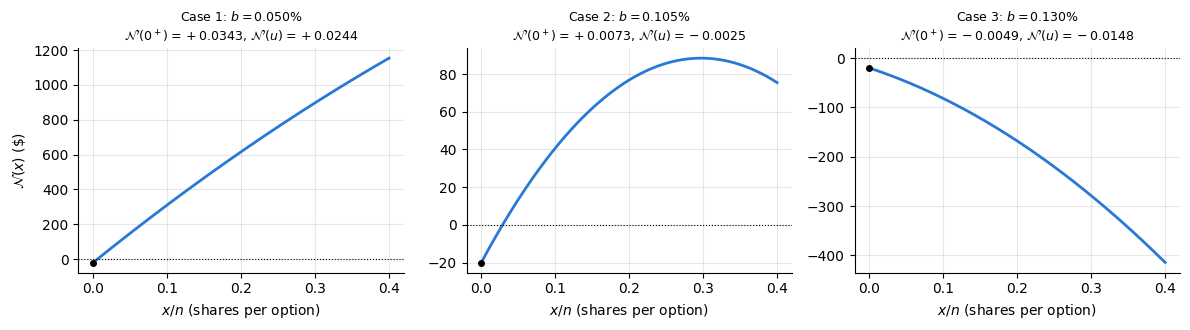

In [3]:
op = mf.one_period()
p, u, k1, k2 = op["p"], op["u"], op["k1"], op["k2"]
S, a = p["S"], p["a"]

for name, b in mf.CASE_B:
    beta = b * S
    print(f"{name}: b = {100*b:.3f}%   N'(0+) = rho'(u) - beta = {k1 + k2*u - beta:+.5f}   "
          f"N'(u) = rho'(0+) - beta = {k1 - beta:+.5f}")
mf.plot_cases(op);

## Section 4 — exponential risk functional

$\rho_{\rm exp}(g) = S\exp(g\mu\tau - \tfrac12 g^2\sigma^2\tau + g\sigma\sqrt\tau)$ with costs
compounded to expiry. Lemma 2 interval for $b$ and the optimal correction (grid maximisation):

Lemma 2 interval: 23.78% < b < 24.52%   (length 0.74 percentage points)
rho_exp(0) = 49.00  (nonzero risk assigned to a zero error)


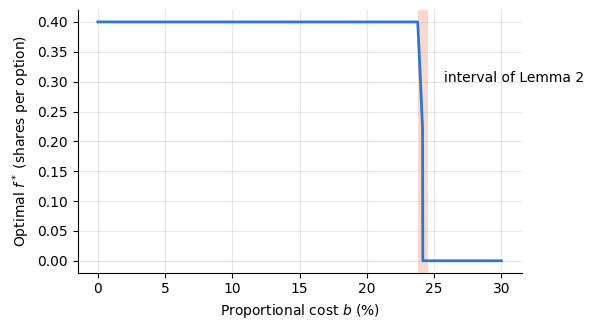

In [4]:
b_lo, b_hi = pr.exp_interval()
print(f"Lemma 2 interval: {100*b_lo:.2f}% < b < {100*b_hi:.2f}%   (length {100*(b_hi-b_lo):.2f} percentage points)")
print(f"rho_exp(0) = {pr.rho_exp(0.0, **pr.EXP_PARAMS):.2f}  (nonzero risk assigned to a zero error)")
mf.plot_first_guess();

## Section 5 — risk functionals

### (a) Variance penalty: $\mathcal F_\gamma[X] = -\gamma^{-1}\log\mathbb E[e^{-\gamma X}]$

For Gaussian $X$ the cumulant expansion terminates: $\mathcal F_\gamma = \mathbb E X - \tfrac{\gamma}{2}\operatorname{Var}X$.
Check by Gauss–Hermite quadrature for several values of $\gamma s$, with $s$ the standard deviation:

In [5]:
nodes, weights = np.polynomial.hermite_e.hermegauss(80)       # probabilists' Hermite, weight exp(-z^2/2)
weights = weights / weights.sum()
m, s = 0.0, 1.0
rows = []
for gs in [0.1, 0.5, 1.0, 2.0]:
    gamma_ = gs / s
    F = -np.log(np.sum(weights * np.exp(-gamma_ * (m + s * nodes)))) / gamma_
    rows.append((gs, F, m - 0.5 * gamma_ * s**2))
pd.DataFrame(rows, columns=["gamma*s", "F_gamma (quadrature)", "E X - gamma Var X / 2"])

,gamma*s,F_gamma (quadrature),E X - gamma Var X / 2
0,0.1000,-0.0500,-0.0500
1,0.5000,-0.2500,-0.2500
2,1.0000,-0.5000,-0.5000
3,2.0000,-1.0000,-1.0000


### (b) Constraint on the standard deviation, and the combined functional

$\rho(g) = k_1|g| + \tfrac12 k_2 g^2$, with $k_1 = \lambda S\sigma\sqrt h$ and $k_2 = \gamma S^2\sigma^2 h$.
Parameters of Section 7:

In [6]:
pd.Series({
    "k1  ($/share)":                 k1,
    "k2  ($/share^2)":               k2,
    "rho'(0+) = k1":                 k1,
    "rho'(u)  = k1 + k2 u":          k1 + k2 * u,
    "b0 = k1/S  (%)":                100 * op["b0"],
    "(k1 + k2 u)/S  (%)":            100 * op["b_hi"],
    "relative width k2 u / k1":      k2 * u / k1,
    "a_c = k2 u^2 / 2  ($)":         op["a_c"],
}).map(lambda v: f"{v:.4g}").to_frame("value")

,value
k1 ($/share),0.04892
k2 ($/share^2),2.456e-07
rho'(0+) = k1,0.04892
rho'(u) = k1 + k2 u,0.05875
b0 = k1/S (%),0.09985
(k1 + k2 u)/S (%),0.1199
relative width k2 u / k1,0.2008
a_c = k2 u^2 / 2 ($),196.5


Note that $a_c = \tfrac12 k_2 u^2 = \rho_{\rm var}(u)$: the partial region exists only if the fixed cost is
smaller than the variance penalty of the full error.

## Section 6 — closed-form solution, verified against grid maximisation

Theorem 1 is compared with a direct maximisation of $\mathcal N$ on a grid of $4\times10^5$ points, for 29
values of $b$ between 0.02% and 0.16%:

In [7]:
worst = mf.check_closed_form(op)
print(f"largest |x_closed_form - x_grid| over the b grid: {worst:.3f} shares (grid spacing {u/4e5:.3f})")

largest |x_closed_form - x_grid| over the b grid: 0.045 shares (grid spacing 0.100)


## Section 7 — numerical example

Table 1 of the paper:

In [8]:
pd.DataFrame(op["examples"], columns=["b", "f* = x*/n", "region", "N(x*) ($)"]).assign(b=lambda d: d.b * 100).rename(columns={"b": "b (%)"})

,b (%),f* = x*/n,region,N(x*) ($)
0,0.0500,0.4000,full,"1,153.4949"
1,0.1050,0.2972,partial,88.4770
2,0.1120,0.1576,partial,10.4883
3,0.1300,0.0000,none,0.0000


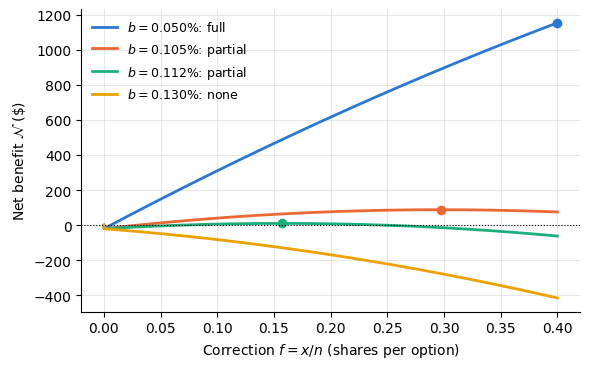

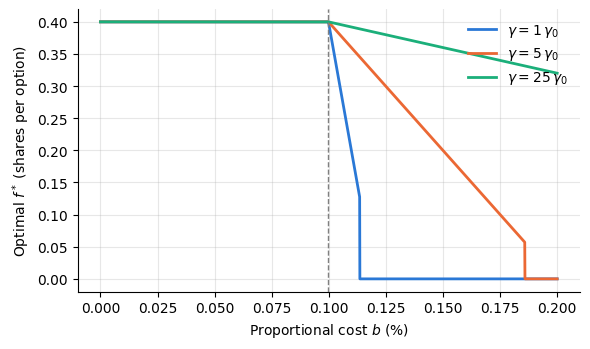

In [9]:
mf.plot_net(op);
mf.plot_fstar(op);

Region boundaries (Proposition 1), drawn over a pointwise evaluation of Theorem 1:

triple point: b0 = 0.0998%,  a_c = $196.51
check: partial|none and full|none boundaries at a = a_c give b = 0.0998% and 0.0998%


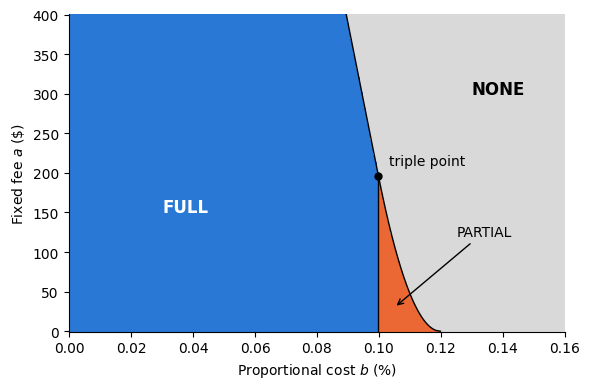

In [10]:
bd = op["bd"]
print(f"triple point: b0 = {100*bd['b0']:.4f}%,  a_c = ${bd['a_c']:.2f}")
print(f"check: partial|none and full|none boundaries at a = a_c give b = "
      f"{100*bd['partial_none'](bd['a_c']):.4f}% and {100*bd['full_none'](bd['a_c']):.4f}%")
mf.plot_regions(op);

## Section 8 — simulation of the complete hedge

Hull's 20-week example, $10^4$ paths, $a = \$20$, $b = 0.1\%$. The rule is applied at 100 dates with
$h = 1/52$, $\gamma = 10^{-5}$ and $\lambda$ a multiple of $\lambda_* = b/(\sigma\sqrt h)$.
Runtime: about 2 minutes.

In [11]:
sims = mf.simulations()
print(f"lambda_* = {sims['lam_star']:.4f},  premium = ${sims['zero'][0][1]['prem']:,.0f}")

zero = pd.DataFrame([(m, r_["mean"], r_["std"] / r_["prem"]) for m, r_ in sims["zero"]],
                    columns=["dates m", "mean P&L ($)", "std / premium"])
zero

lambda_* = 0.0361,  premium = $240,053


,dates m,mean P&L ($),std / premium
0,5,-242.0255,0.3697
1,20,-129.9842,0.1890
2,80,-11.1487,0.0971


In [12]:
rows = [("full", m, np.nan, r_["trades"], r_["cost"], r_["std"]) for m, r_ in sims["full"]]
rows += [("rule", pr.SIM["n_steps"], k, r_["trades"], r_["cost"], r_["std"]) for k, r_ in sims["rule"]]
dyn = pd.DataFrame(rows, columns=["strategy", "dates", "lambda / lambda_*", "trades", "mean cost ($)", "std P&L ($)"])
dyn.style.format({"lambda / lambda_*": "{:.1f}", "trades": "{:.1f}", "mean cost ($)": "{:,.0f}", "std P&L ($)": "{:,.0f}"}, na_rep="-")

,strategy,dates,lambda / lambda_*,trades,mean cost ($),std P&L ($)
0,full,5,-,5.0,"5,537","89,238"
1,full,10,-,10.0,"7,275","64,230"
2,full,20,-,20.0,"9,557","45,928"
3,full,50,-,49.9,"14,223","29,902"
4,full,100,-,99.6,"19,789","22,059"
5,rule,100,0.0,37.0,"11,561","26,410"
6,rule,100,0.5,46.6,"14,053","23,526"
7,rule,100,0.9,58.4,"17,200","22,389"
8,rule,100,1.1,65.9,"18,517","22,231"
9,rule,100,2.0,82.0,"19,359","22,110"


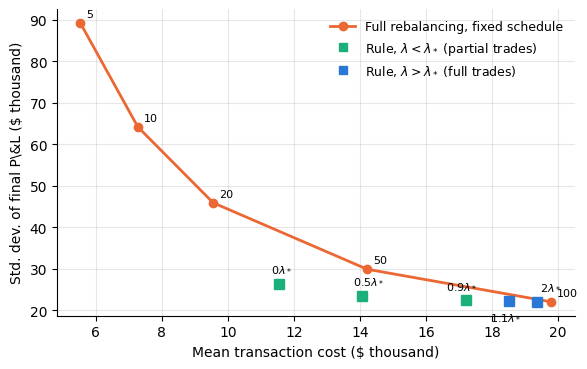

In [13]:
mf.plot_dynamic(sims);